In [1]:
import pandas as pd
import os
from google.colab import drive

In [2]:
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
feat = pd.read_csv("/content/drive/MyDrive/BTT_Amazon1A_Studio/feat.csv")

In [ ]:
feat.head()

,Customer ID,SnapshotMonth,month_orders,month_revenue,month_quantity,month_diff_items,month_last_order,month_cancellations,cancellation_rate,churn,snapshot_end,last_order,first_order,total_orders,tenure_days,recency_days,frequency,orders_30d,orders_60d,orders_90d
0,12346,2009-12,2.0,113.50,26.0,2.0,2009-12-18 10:55:00,0.0,0.000000,0,2009-12-31,2009-12-18 10:55:00,2009-12-14 08:34:00,5.0,16.0,12.0,5.0,5.0,5.0,5.0
1,14606,2009-12,11.0,1401.59,527.0,210.0,2009-12-21 14:33:00,12.0,1.090909,0,2009-12-31,2009-12-21 14:33:00,2009-12-03 12:40:00,8.0,27.0,9.0,8.0,8.0,8.0,8.0
2,14605,2009-12,1.0,208.60,133.0,31.0,2009-12-08 13:59:00,0.0,0.000000,1,2009-12-31,2009-12-08 14:01:00,2009-12-08 13:59:00,2.0,22.0,22.0,2.0,2.0,2.0,2.0
3,14593,2009-12,1.0,391.68,157.0,65.0,2009-12-09 12:57:00,2.0,2.000000,0,2009-12-31,2009-12-09 12:57:00,2009-12-09 12:57:00,1.0,21.0,21.0,1.0,1.0,1.0,1.0
4,14590,2009-12,3.0,349.66,108.0,38.0,2009-12-16 11:26:00,0.0,0.000000,0,2009-12-31,2009-12-16 11:26:00,2009-12-07 14:10:00,3.0,23.0,14.0,3.0,3.0,3.0,3.0


In [ ]:
feat.columns

Index(['Customer ID', 'SnapshotMonth', 'month_orders', 'month_revenue',
       'month_quantity', 'month_diff_items', 'month_last_order',
       'month_cancellations', 'cancellation_rate', 'churn', 'snapshot_end',
       'last_order', 'first_order', 'total_orders', 'tenure_days',
       'recency_days', 'frequency', 'orders_30d', 'orders_60d', 'orders_90d'],
      dtype='object')

In [4]:
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier


FEATURES = ["cancellation_rate","total_orders", "tenure_days",
            "recency_days", "frequency", "orders_30d", "orders_60d",
            "orders_90d", "month_orders", "month_revenue", "month_quantity",
            "month_diff_items", "month_cancellations"]

X = feat[FEATURES]
y = feat['churn']

#train and test splits
X_train,X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.1,
    random_state=42
    )
model.fit(X_train,y_train)

model_preds = model.predict_proba(X_test)
model_predictions = list(model_preds[:,-1])#churn probabilities



In [5]:

from sklearn.metrics import accuracy_score

xgb_pred = model.predict(X_test)

xgb_acc = accuracy_score(y_test,xgb_pred)

print(f"XGBoost accuracy score: {xgb_acc}")

XGBoost accuracy score: 0.8096590909090909


In [6]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [300, 500, 800],
    "max_depth": [3, 4, 6, 8],
    "learning_rate": [0.05, 0.1, 0.15],
}

grid_search = GridSearchCV(
    estimator=XGBClassifier(random_state=42, eval_metric='logloss'),
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose=2
)

grid_search.fit(X_train, y_train)

print(f"hyperparameters: {grid_search.best_params_}")
print(f"best validation f1 score: {grid_search.best_score_:.4f}")

Fitting 5 folds for each of 36 candidates, totalling 180 fits
hyperparameters: {'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 500}
best validation f1 score: 0.5093


In [7]:
#model already refit with best hyperparameters
xgb_tuned_model = grid_search.best_estimator_

#gets the predicted probability that each cutomer will churn
xgb_tuned_preds = xgb_tuned_model.predict_proba(X_test)
xgb_tuned_predictions = list(xgb_tuned_preds[:, -1])

#predict class labels for test data
xgb_tuned_pred = xgb_tuned_model.predict(X_test)

#calculate accuracy scores
xgb_tuned_acc = accuracy_score(y_test, xgb_tuned_pred)

#print results
print(f"tuned XGBoost accuracy score: {xgb_tuned_acc}")

tuned XGBoost accuracy score: 0.8044507575757576


                    Precision  Recall      F1  ROC-AUC  PR-AUC
Model                                                         
XGBoost (baseline)     0.5793  0.4292  0.4931   0.8452  0.5540
XGBoost (tuned)        0.5612  0.4281  0.4857   0.8414  0.5467

Churn rate in test set: 0.2157

XGBoost (baseline)
[[3029  284]
 [ 520  391]]
              precision    recall  f1-score   support

           0     0.8535    0.9143    0.8828      3313
           1     0.5793    0.4292    0.4931       911

    accuracy                         0.8097      4224
   macro avg     0.7164    0.6717    0.6879      4224
weighted avg     0.7943    0.8097    0.7988      4224


XGBoost (tuned)
[[3008  305]
 [ 521  390]]
              precision    recall  f1-score   support

           0     0.8524    0.9079    0.8793      3313
           1     0.5612    0.4281    0.4857       911

    accuracy                         0.8045      4224
   macro avg     0.7068    0.6680    0.6825      4224
weighted avg     0.7896   

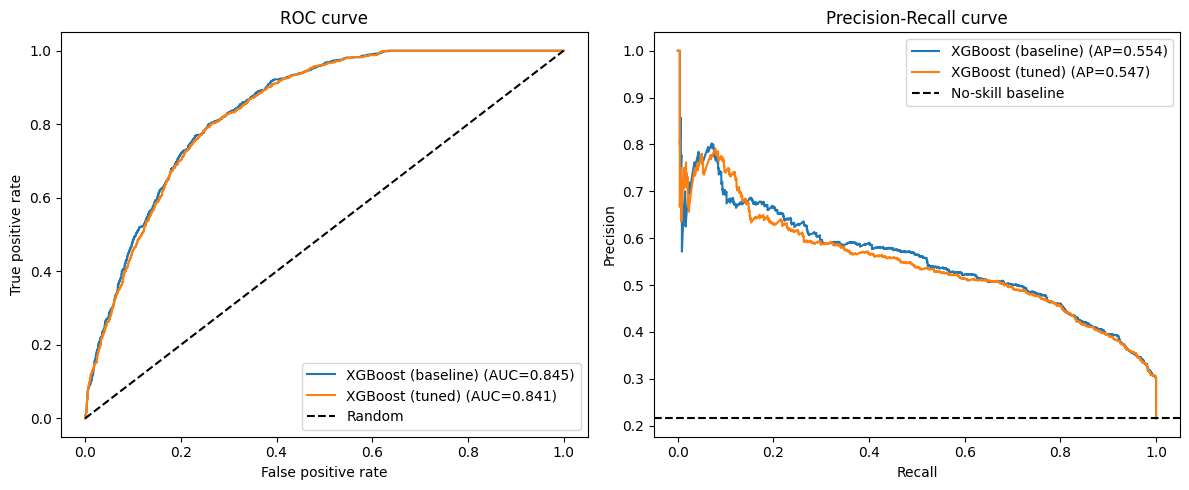

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    roc_curve, precision_recall_curve,
    confusion_matrix, classification_report
)

# probabilities of churn (class 1) and hard labels for each model
models = {
    "XGBoost (baseline)": {
        "proba": model.predict_proba(X_test)[:, 1],
        "pred": xgb_pred,
    },
    "XGBoost (tuned)": {
        "proba": xgb_tuned_model.predict_proba(X_test)[:, 1],
        "pred": xgb_tuned_pred,
    },
}

# metrics table
rows = []
for name, m in models.items():
    rows.append({
        "Model": name,
        "Precision": precision_score(y_test, m["pred"]),
        "Recall": recall_score(y_test, m["pred"]),
        "F1": f1_score(y_test, m["pred"]),
        "ROC-AUC": roc_auc_score(y_test, m["proba"]),
        "PR-AUC": average_precision_score(y_test, m["proba"]),
    })

results = pd.DataFrame(rows).set_index("Model").round(4)
print(results)

# class balance, which is the baseline PR-AUC to compare against
print(f"\nChurn rate in test set: {y_test.mean():.4f}")

# confusion matrices + per-class report
for name, m in models.items():
    print(f"\n{name}")
    print(confusion_matrix(y_test, m["pred"]))
    print(classification_report(y_test, m["pred"], digits=4))

# ROC and PR curves
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

for name, m in models.items():
    fpr, tpr, _ = roc_curve(y_test, m["proba"])
    ax[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, m['proba']):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, m["proba"])
    ax[1].plot(rec, prec, label=f"{name} (AP={average_precision_score(y_test, m['proba']):.3f})")

ax[0].plot([0, 1], [0, 1], "k--", label="Random")
ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate")
ax[0].set_title("ROC curve"); ax[0].legend()

ax[1].axhline(y_test.mean(), color="k", linestyle="--", label="No-skill baseline")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision")
ax[1].set_title("Precision-Recall curve"); ax[1].legend()

plt.tight_layout()
plt.show()

## Model Evaluation: Baseline vs. Tuned XGBoost

Precision, recall, and F1 use the default 0.5 threshold on the churn class. ROC-AUC and PR-AUC use the predicted probabilities.

| Model | Precision | Recall | F1 | ROC-AUC | PR-AUC |
|---|---|---|---|---|---|
| XGBoost (baseline) | 0.5793 | 0.4292 | 0.4931 | 0.8452 | 0.5540 |
| XGBoost (tuned) | 0.5612 | 0.4281 | 0.4857 | 0.8414 | 0.5467 |

### Takeaways

**Tuning didn't help.** The baseline scored slightly higher than the tuned model on every metric. The gaps are small (F1 differs by about 0.007, ROC-AUC by about 0.004), so I'd call them roughly equal, but the grid search didn't improve on the original settings. The baseline was already close to what this feature set can support.

**Accuracy overstates performance.** Both models land around 80-81% accuracy, but only about 78% of customers don't churn, so a model that predicted "no churn" for everyone would already get roughly 78%. Precision, recall, and F1 on the churn class show the real picture.

**The models find fewer than half of the churners.** The baseline caught 391 of 911 churners (recall 0.43) and missed 520. When it flagged someone as likely to churn, it was right about 58% of the time (precision 0.58). The tuned model is nearly identical: 390 caught, 521 missed, and slightly more false alarms (305 vs. 284).

**Ranking is decent even though the hard labels are not great.** ROC-AUC is about 0.84, so the models are good at putting churners above non-churners in the probability ranking. PR-AUC is about 0.55, compared with 0.22 for a no-skill model (the churn rate), so that's roughly 2.5x better than chance. It's still well below 1, which matches the precision and recall.

### Limitations and next steps

- **Threshold:** all precision, recall, and F1 numbers come from the default 0.5 cutoff. Since recall on churners is low, we could lower the threshold to catch more churners at the cost of precision. The right tradeoff depends on what a missed churner costs versus a wasted retention offer.
